# Tahap 3 — Literature-Grounded Aspect Taxonomy & Annotation Guidelines

## 1. Research Context

**Tujuan.** Menyusun taksonomi, schema, pedoman, desain pilot dan QA untuk ABSA coffee shop BrewScope. Semua contoh anotasi di notebook ini **sintetis**. Belum dilakukan labeling manusia/AI terhadap review asli.

**Metode.** Triangulasi literatur primer, hasil agregat Tahap 2, dan eksplorasi keyword yang transparan. Raw hanya diakses untuk memeriksa hash dan menghitung indikator leksikal; isinya tidak ditampilkan atau dikirim ke layanan eksternal. Analisis tidak melatih model.

**Batas.** Semua 40 lokasi UNVERIFIED dan hak anotasi/training/publikasi PERMISSION_NOT_VERIFIED. Penyusunan metodologi dan kandidat pilot tidak menyatakan gate itu telah terpenuhi.


In [1]:
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from jsonschema import Draft202012Validator

get_ipython().run_line_magic("matplotlib", "inline")
ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "pyproject.toml").is_file() and (p / "PROJECT_CONTEXT.md").is_file()), None
)
if ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari repository BrewScope.")
RAW_PATH = ROOT / "data/raw/google_maps_reviews_jatinangor_raw.csv"
TABLES = ROOT / "reports/tables"
FIGURES = ROOT / "reports/figures"
CANDIDATE_PATH = ROOT / "data/interim/annotation_pilot_candidates.csv"
CONFIG_PATH = ROOT / "configs/aspect_taxonomy.yaml"
SCHEMA_PATH = ROOT / "schemas/annotation_schema.json"
for directory in (TABLES, FIGURES, CANDIDATE_PATH.parent):
    directory.mkdir(parents=True, exist_ok=True)
stage2 = json.loads((ROOT / "reports/data_audit_summary.json").read_text(encoding="utf-8"))
taxonomy = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
literature = pd.read_csv(TABLES / "literature_matrix.csv", keep_default_na=False)
geo = pd.read_csv(TABLES / "geographic_verification.csv", keep_default_na=False)
flags = pd.read_csv(ROOT / "data/interim/review_audit_flags.csv", dtype={"review_id": "string"})
raw = pd.read_csv(RAW_PATH, dtype="string", keep_default_na=False)
SOURCE_SHA256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
assert SOURCE_SHA256 == stage2["source_sha256"], "Snapshot berubah; audit Tahap 2 harus diperbarui."
assert len(raw) == stage2["overview"]["total_reviews"] == len(flags)
assert flags["review_id"].is_unique and raw["review_id"].is_unique
assert set(flags["review_id"]) == set(raw["review_id"])
ASPECT_NAMES = {a["id"]: a["name"] for a in taxonomy["aspects"] if a["active"]}
ACTIVE_IDS = list(ASPECT_NAMES)
SEED = taxonomy["sampling"]["seed"]
plt.rcParams.update({"font.size": 10, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})
print("Versi:", taxonomy["taxonomy_version"], "| Hash sumber:", SOURCE_SHA256)
print("Batas kerja: metodologi, validasi sintetis, dan pemilihan kandidat tanpa label.")


Versi: 0.1.0-draft | Hash sumber: 7b87a53110041da74e976a6c9cb121c1dea7d73be70daeab58b2c07bef775719
Batas kerja: metodologi, validasi sintetis, dan pemilihan kandidat tanpa label.


## 2. Stage 2 Findings

**Metode.** Baca ringkasan/flag Tahap 2 tanpa menjalankan ulang EDA atau mengubah grafiknya. Angka di bawah diverifikasi terhadap snapshot yang sama.

**Interpretasi.** Metadata rating dipakai untuk memperkaya rancangan sampling saja. Dominasi rating 5 bukan prevalensi sentimen aspek. Simbol/emoji-only merupakan masalah kelayakan teks, bukan konflik ID.


In [2]:
stage2_overview = {
    "review": len(raw), "coffee_shops": flags["place_key"].nunique(),
    "eligible_teknis": int(flags["passes_basic_quality"].sum()),
    "symbol_only": int(flags["is_symbol_only"].sum()),
    "short_review": int(flags["is_short_review"].sum()),
    "tanpa_keyword": stage2["no_aspect_keyword_rows"],
    "multi_keyword": stage2["multi_aspect_keyword_rows"],
    "rating_5_pct": stage2["rating_distribution"][4]["pct_of_all_reviews"],
}
display(pd.Series(stage2_overview, name="hasil aktual").to_frame())
display(pd.DataFrame(stage2["aspect_distribution"]).round(2))
display(Markdown(
    f"**Interpretasi.** Ada {stage2_overview['tanpa_keyword']:,} review tanpa keyword dan "
    f"{stage2_overview['multi_keyword']:,} review dengan ≥2 indikator. Keduanya perlu "
    "diwakili pada pilot; keyword absence tidak dapat menjadi label not_mentioned."
))


,hasil aktual
review,3593.000000
coffee_shops,40.000000
eligible_teknis,3582.000000
symbol_only,11.000000
short_review,778.000000
tanpa_keyword,1052.000000
multi_keyword,1309.000000
rating_5_pct,85.471751


,aspect,review_mentions,coverage_pct
0,Product Quality,1452,40.41
1,Service,889,24.74
2,Price & Value,430,11.97
3,Ambience,1343,37.38
4,Facilities,277,7.71
5,Cleanliness,175,4.87


**Interpretasi.** Ada 1,052 review tanpa keyword dan 1,309 review dengan ≥2 indikator. Keduanya perlu diwakili pada pilot; keyword absence tidak dapat menjadi label not_mentioned.

## 3. Literature Review Summary

**Tujuan/metode.** Verifikasi judul, penulis, tahun, venue, DOI, kategori yang benar-benar disebutkan, dan lokasi bukti melalui publisher/ACL. Tinjauan bersifat terarah, bukan systematic review yang mengklaim menyeluruh.

**Hasil.** Matriks di bawah berasal dari penelitian sumber primer. Status abstract-only tidak dianggap bukti protokol full text. Catatan lengkap: [literature review](../docs/research/aspect_taxonomy_literature_review.md) dan [BibTeX](../docs/research/references.bib).


In [3]:
required_literature = {
    "source_id", "authors", "year", "title", "venue", "doi", "url", "domain",
    "dataset_source", "aspect_categories", "identification_method", "relevance",
    "evidence_location", "verification_status",
}
assert required_literature.issubset(literature.columns)
assert literature["source_id"].is_unique and literature["doi"].is_unique
assert not literature[list(required_literature)].eq("").any().any()
bib = (ROOT / "docs/research/references.bib").read_text(encoding="utf-8")
bib_ids = set(re.findall(r"@\w+\{([^,]+),", bib))
assert set(literature["source_id"]) == bib_ids
for paper in literature.itertuples(index=False):
    assert paper.doi in bib
display(literature[["source_id", "year", "title", "doi", "verification_status"]])
status_counts = literature["verification_status"].value_counts()
display(Markdown(
    f"**Interpretasi.** {len(literature)} sumber terverifikasi bibliografinya; "
    f"{int(status_counts.get('VERIFIED_FULL_TEXT', 0))} full text relevan dan "
    f"{int(status_counts.get('VERIFIED_METADATA_AND_ABSTRACT', 0))} metadata/abstrak. "
    "Sumber survei mendukung dimensi pengalaman, bukan validasi enam label ABSA. "
    "Ketidakjelasan absence/neutral dan prosedur labeling pada studi lain tidak diwariskan."
))


,source_id,year,title,doi,verification_status
0,pontiki2014,2014,SemEval-2014 Task 4: Aspect Based Sentiment An...,10.3115/v1/S14-2004,VERIFIED_FULL_TEXT
1,pontiki2016,2016,SemEval-2016 Task 5: Aspect Based Sentiment An...,10.18653/v1/S16-1002,VERIFIED_FULL_TEXT
2,zainuddin2025,2025,Studi Perbandingan Kepuasan Pelanggan pada Ked...,10.31331/joined.v8i2.4325,VERIFIED_METADATA_AND_ABSTRACT
3,latifah2026,2026,Perbandingan Hasil Aspect-Based Sentiment Anal...,10.35315/dinamik.v31i1.10417,VERIFIED_FULL_TEXT
4,suksarifanti2024,2024,Consumer Satisfaction of Coffee Shops in Ponor...,10.22146/jamadev.v5i1.12984,VERIFIED_FULL_TEXT
5,wiastuti2024,2024,Customer-perceived importance of restaurant at...,10.18778/0867-5856.34.2.02,VERIFIED_FULL_TEXT
6,zanetta2024,2024,How does the consumer choose a restaurant? An ...,10.1016/j.foodres.2024.114369,VERIFIED_METADATA_AND_ABSTRACT


**Interpretasi.** 7 sumber terverifikasi bibliografinya; 5 full text relevan dan 2 metadata/abstrak. Sumber survei mendukung dimensi pengalaman, bukan validasi enam label ABSA. Ketidakjelasan absence/neutral dan prosedur labeling pada studi lain tidak diwariskan.

## 4. Literature-to-Aspect Mapping

**Metode.** Hubungkan setiap kandidat dengan sumber dan evidence location. ADOPT berlaku pada makna konsep; ADAPT menandai perubahan cakupan/pengelompokan oleh BrewScope. Inventory E#A, kategori ABSA, dan item survei tidak dianggap identik.

**Implikasi.** Pemetaan ini merupakan argumen metodologis, bukan hasil anotasi atau ukuran akurasi.


In [4]:
source_index = literature.set_index("source_id")
mapping_rows = []
for aspect in taxonomy["aspects"]:
    for source_id in aspect["sources"]:
        assert source_id in source_index.index
        paper = source_index.loc[source_id]
        support_type = (
            "SURVEY_ATTRIBUTE_ADAPTATION" if source_id in {"suksarifanti2024", "wiastuti2024"}
            else "ABSTRACT_ASPECT_LIST" if source_id == "zainuddin2025" else "ABSA_CATEGORY"
        )
        mapping_rows.append({
            "aspect_id": aspect["id"], "aspect_name": aspect["name"],
            "active": aspect["active"], "decision": aspect["decision"],
            "source_id": source_id, "year": int(paper["year"]), "doi": paper["doi"],
            "source_original_inventory": paper["aspect_categories"],
            "support_type": support_type, "evidence_location": paper["evidence_location"],
            "verification_status": paper["verification_status"],
            "researcher_adaptation": aspect["justification"],
        })
mapping = pd.DataFrame(mapping_rows)
assert not mapping.duplicated(["aspect_id", "source_id"]).any()
assert set(mapping["aspect_id"]) == {a["id"] for a in taxonomy["aspects"]}
mapping.to_csv(TABLES / "literature_aspect_mapping.csv", index=False, encoding="utf-8-sig")
display(mapping[["aspect_id", "source_id", "support_type", "decision", "evidence_location"]])
display(Markdown(
    "**Interpretasi.** Waiting time masuk Service; FOOD/DRINKS/menu masuk Product Quality. "
    "Pemisahan fungsi amenitas dan kebersihan adalah adaptasi penelitian, bukan klaim "
    "bahwa sumber survei menggunakan enam kategori ABSA BrewScope."
))


,aspect_id,source_id,support_type,decision,evidence_location
0,product_quality,pontiki2014,ABSA_CATEGORY,ADAPT,PDF §2 p28; §3 Stage2 p30; Table3 p31
1,product_quality,pontiki2016,ABSA_CATEGORY,ADAPT,PDF §2 pp20–21; AppendixA Table11 p30
2,product_quality,zainuddin2025,ABSTRACT_ASPECT_LIST,ADAPT,Landing page Abstract dan metadata Published/H...
3,product_quality,latifah2026,ABSA_CATEGORY,ADAPT,PDF §3 pp324–325; §3.4 p325; §4.1/Table2 dan §...
4,product_quality,suksarifanti2024,SURVEY_ATTRIBUTE_ADAPTATION,ADAPT,PDF Method p47; Table3 p50; Table4 p51 (PL1/2/...
5,service,pontiki2014,ABSA_CATEGORY,ADOPT,PDF §2 p28; §3 Stage2 p30; Table3 p31
6,service,pontiki2016,ABSA_CATEGORY,ADOPT,PDF §2 pp20–21; AppendixA Table11 p30
7,service,zainuddin2025,ABSTRACT_ASPECT_LIST,ADOPT,Landing page Abstract dan metadata Published/H...
8,service,latifah2026,ABSA_CATEGORY,ADOPT,PDF §3 pp324–325; §3.4 p325; §4.1/Table2 dan §...
9,service,suksarifanti2024,SURVEY_ATTRIBUTE_ADAPTATION,ADOPT,PDF Method p47; Table3 p50; Table4 p51 (PL1/2/...


**Interpretasi.** Waiting time masuk Service; FOOD/DRINKS/menu masuk Product Quality. Pemisahan fungsi amenitas dan kebersihan adalah adaptasi penelitian, bukan klaim bahwa sumber survei menggunakan enam kategori ABSA BrewScope.

## 5. Candidate Taxonomy

**Metode.** Validasi struktur YAML, konsistensi ID, sumber, keputusan dan tiga contoh polaritas sintetis per kandidat. Definisi lengkap, inclusion/exclusion, explicit/implicit, overlap, dan alasan terdapat di YAML.

**Hasil.** Enam aspek aktif masih berstatus draft; kandidat ketujuh tetap provisional.


In [5]:
assert taxonomy["taxonomy_version"] == "0.1.0-draft"
assert taxonomy["examples_origin"] == "SYNTHETIC_ONLY"
assert len({a["id"] for a in taxonomy["aspects"]}) == len(taxonomy["aspects"])
assert set(schema["properties"]["aspect_category"]["enum"]) == set(ACTIVE_IDS)
for aspect in taxonomy["aspects"]:
    for field in ("operational_definition", "sources", "inclusion", "exclusion",
                  "explicit_expressions", "implicit_expressions", "examples", "overlaps", "justification"):
        assert aspect[field], (aspect["id"], field)
    assert set(aspect["examples"]) == {"positive", "neutral", "negative"}
    assert set(aspect["sources"]).issubset(set(literature["source_id"]))
    assert aspect["decision"] in {"ADOPT", "ADAPT", "MERGE", "REJECT", "PROVISIONAL"}
display(pd.DataFrame([{
    "id": a["id"], "nama": a["name"], "decision": a["decision"],
    "aktif": a["active"], "definisi": a["operational_definition"],
} for a in taxonomy["aspects"]]))


,id,nama,decision,aktif,definisi
0,product_quality,Product Quality,ADAPT,True,"Kualitas intrinsik makanan/minuman, rasa, kese..."
1,service,Service,ADOPT,True,"Interaksi dan proses layanan staf: keramahan, ..."
2,price_value,Price & Value,ADAPT,True,"Evaluasi harga, keterjangkauan, promosi, dan k..."
3,ambience,Ambience,ADAPT,True,"Pengalaman suasana dan kenyamanan: interior, k..."
4,facilities,Facilities,ADAPT,True,"Keberadaan, kapasitas, fungsi, dan kemudahan m..."
5,cleanliness,Cleanliness,ADAPT,True,"Keadaan bersih/higienis ruang, meja, toilet, p..."
6,location_accessibility,Location & Accessibility,PROVISIONAL,False,"Kenyamanan posisi geografis, kemudahan menemuk..."


## 6. Taxonomy Adaptation Decisions

**Metode.** Bandingkan inventori asli studi dengan kebutuhan batas kategori lokal, tidak hanya frekuensi keyword. Penolakan miscellaneous sebagai kategori operasional bukan penolakan bahwa konsep umum itu ada dalam literatur.

**Interpretasi.** General praise perlu workflow gap/uncertainty, bukan semua aspek positif. Location memiliki dasar teori tetapi belum cukup bukti lokal yang berizin untuk finalisasi.


In [6]:
display(pd.DataFrame(taxonomy["adaptation_decisions"]))
provisional = [a for a in taxonomy["aspects"] if not a["active"]]
for aspect in provisional:
    display(Markdown(f"**{aspect['name']} — {aspect['decision']}.** {aspect['justification']}"))
print("Keputusan draft akan diuji lagi setelah pilot manusia berizin; belum empirically validated.")


,candidate,decision,destination,reason
0,Food + Drinks + Menu/Porsi,MERGE,product_quality,Granularitas kategori operasional coffee shop.
1,Waiting Time,MERGE,service,Proses layanan; pertahankan evidence granular ...
2,General Praise / Miscellaneous,REJECT,workflow_gap,Tidak menjadi label sentimen per aspek; pujian...
3,Facilities versus Cleanliness,ADAPT,dua kategori aktif,Pisahkan fungsi amenitas dari kondisi kebersih...


**Location & Accessibility — PROVISIONAL.** Landasan literatur ada, tetapi coverage lokal belum diaudit dengan protokol yang memadai dan scope administratif belum pasti. Uji pada pilot berizin sebelum aktivasi.

Keputusan draft akan diuji lagi setelah pilot manusia berizin; belum empirically validated.


## 7. Empirical Coverage Exploration

**Tujuan.** Mengevaluasi indikasi coverage, overlap, dan kesenjangan dari agregat Tahap 2.

**Metode.** Gunakan kamus keyword Tahap 2 persis dengan boundary Unicode yang sama. Hitung jumlah review per indikator dan pasangan indikator/Jaccard tanpa menilai apakah aspek benar-benar hadir. Tidak ditampilkan teks review asli atau dibuat sentimen. Fungsi bertag stage3-core juga mengimplementasikan sampling dan validasi **sintetis** agar dapat diuji tanpa module terpisah.

**Keterbatasan.** Review tanpa keyword hanya kandidat untuk memeriksa aspek implisit/out-of-taxonomy kelak. Belum diketahui apakah benar tidak sesuai taksonomi. Location & Accessibility tidak diukur melalui tebakan atau anotasi saat ini.


In [7]:
def keyword_indicators(texts, historical_keywords, names):
    result = {}
    for aspect_id, name in names.items():
        keywords = historical_keywords[name]
        pattern = re.compile(
            r"(?<!\w)(?:" + "|".join(
                re.escape(k).replace(r"\ ", r"\s+")
                for k in sorted(keywords, key=len, reverse=True)
            ) + r")(?!\w)", re.IGNORECASE,
        )
        result[aspect_id] = texts.fillna("").astype(str).map(lambda text: bool(pattern.search(text)))
    return pd.DataFrame(result, index=texts.index)


def sampling_frame(source, audit_flags, historical_keywords, names):
    if not source["review_id"].is_unique or not audit_flags["review_id"].is_unique:
        raise ValueError("ID review harus unik untuk pencocokan metadata.")
    if set(source["review_id"]) != set(audit_flags["review_id"]):
        raise ValueError("Review ID raw dan flag berbeda.")
    fields = [
        "review_id", "place_key", "nama_tempat", "rating", "word_count",
        "passes_basic_quality", "confirmed_duplicate_extra", "is_short_review",
        "has_slang_hint", "possible_mixed_language", "potential_text_duplicate",
    ]
    base = audit_flags[fields].copy().reset_index(drop=True)
    for flag in fields[5:]:
        if not pd.api.types.is_bool_dtype(base[flag]):
            raise ValueError(f"Flag harus boolean: {flag}")
    texts = source.set_index("review_id").loc[base["review_id"], "teks_review"].reset_index(drop=True)
    indicators = keyword_indicators(texts, historical_keywords, names)
    for aspect_id in names:
        base["keyword_" + aspect_id] = indicators[aspect_id].to_numpy()
    base["keyword_count"] = indicators.sum(axis=1)
    base["exploratory_keyword_indicators"] = indicators.apply(
        lambda row: ";".join(aspect_id for aspect_id in names if row[aspect_id]), axis=1,
    )
    normalized = texts.fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str.casefold()
    base["duplicate_text_group"] = normalized.map(
        lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
    )
    base["shop_review_count"] = base.groupby("place_key")["review_id"].transform("size")
    return base, indicators


def pilot_groups(frame):
    rating = pd.to_numeric(frame["rating"], errors="coerce")
    return {
        "rare_cleanliness": frame["keyword_cleanliness"],
        "facilities_candidate": frame["keyword_facilities"],
        "no_keyword": frame["keyword_count"].eq(0),
        "low_rating": rating.isin([1, 2]), "mid_rating": rating.eq(3),
        "long_review": frame["word_count"].gt(30),
        "multi_keyword": frame["keyword_count"].ge(2),
        "slang_or_mixed": frame["has_slang_hint"] | frame["possible_mixed_language"],
        "potential_duplicate": frame["potential_text_duplicate"],
        "short_review": frame["is_short_review"],
        "small_shop": frame["shop_review_count"].lt(30),
        "high_rating": rating.isin([4, 5]),
    }


def select_pilot(frame, policy):
    pool = frame.loc[frame["passes_basic_quality"] & ~frame["confirmed_duplicate_extra"]].copy()
    if pool.empty:
        raise ValueError("Tidak ada kandidat eligible.")
    if not pool["review_id"].is_unique:
        raise ValueError("Kandidat memiliki ID duplikat.")
    target = min(int(policy["target"]), len(pool))
    seed = int(policy["seed"])
    pool["selection_hash"] = pool["review_id"].map(
        lambda rid: hashlib.sha256(f"{seed}|{rid}".encode("utf-8")).hexdigest()
    )
    pool = pool.sort_values(["selection_hash", "review_id"], kind="stable").reset_index(drop=True)
    selected = {}
    minimum = int(policy["minimum_per_shop"])
    for _, group in pool.groupby("place_key", sort=True):
        for rid in group.head(minimum)["review_id"]:
            selected[rid] = ["minimum_per_shop"]
    if len(selected) > target:
        raise ValueError("Target lebih kecil daripada alokasi minimum per kedai.")
    groups = pilot_groups(pool)
    for name, required in policy["quota_targets"].items():
        mask = groups[name]
        actual = int((pool["review_id"].isin(selected) & mask).sum())
        need = max(0, int(required) - actual)
        remaining = max(0, target - len(selected))
        candidates = pool.loc[mask & ~pool["review_id"].isin(selected)].head(min(need, remaining))
        for rid in candidates["review_id"]:
            selected[rid] = ["quota:" + name]
    for rid in pool.loc[~pool["review_id"].isin(selected), "review_id"]:
        if len(selected) >= target:
            break
        selected[rid] = ["fill_remaining"]
    sample = pool.loc[pool["review_id"].isin(selected)].copy()
    sample["sampling_reason"] = sample["review_id"].map(lambda rid: ";".join(selected[rid]))
    sample["seed"] = seed
    sample["selection_order"] = range(1, len(sample) + 1)
    sample["candidate_status"] = "UNLABELED_NOT_AUTHORIZED"
    selected_mask = pool["review_id"].isin(selected)
    quota = pd.DataFrame([{
        "group": name, "target_minimum": int(required),
        "available_in_eligible_pool": int(groups[name].sum()),
        "selected_count": int((selected_mask & groups[name]).sum()),
        "shortfall": max(0, int(required) - int((selected_mask & groups[name]).sum())),
    } for name, required in policy["quota_targets"].items()])
    assert len(sample) == target and sample["review_id"].is_unique
    assert not {"review_text", "teks_review", "sentiment", "aspect_presence", "annotation_status", "evidence"}.intersection(sample.columns)
    return sample.reset_index(drop=True), quota


def validate_annotation(record, annotation_schema, synthetic_only=True):
    Draft202012Validator(annotation_schema).validate(record)
    if synthetic_only and (
        record["data_origin"] != "synthetic" or not record["review_id"].startswith("SYN_")
    ):
        raise ValueError("Tahap 3 hanya memvalidasi anotasi sintetis.")
    for opinion in record["evidence"]:
        if not opinion["start"] < opinion["end"] <= len(record["review_text"]):
            raise ValueError("Rentang evidence tidak valid.")
        if record["review_text"][opinion["start"]:opinion["end"]] != opinion["quote"]:
            raise ValueError("Quote harus sama dengan slice teks asli.")
    polarities = {o["opinion_sentiment"] for o in record["evidence"]}
    if record["annotation_status"] == "completed" and None in polarities:
        raise ValueError("Opini yang belum terselesaikan tidak boleh completed.")
    both = {"positive", "negative"}.issubset(polarities)
    if both != record["mixed_sentiment"]:
        raise ValueError("Mixed harus mempertahankan bukti positif dan negatif.")
    if record["aspect_presence"] == "mentioned":
        types = {o["mention_type"] for o in record["evidence"]}
        expected = next(iter(types)) if len(types) == 1 else "mixed"
        if record["mention_type"] != expected:
            raise ValueError("Mention type ringkasan tidak cocok dengan evidence.")
        if record["annotation_status"] == "completed" and not both:
            actual = polarities - {"neutral"}
            if None in polarities or (actual and record["sentiment"] not in actual):
                raise ValueError("Sentimen ringkasan bertentangan dengan evidence.")
            if not actual and record["sentiment"] != "neutral":
                raise ValueError("Evidence hanya netral harus diringkas netral.")
    return True


def validate_batch(records, annotation_schema):
    seen = set()
    for record in records:
        validate_annotation(record, annotation_schema)
        key = (record["review_id"], record["aspect_category"], record["annotator_id"], record["taxonomy_version"])
        if key in seen:
            raise ValueError("Pair review–aspect–annotator duplikat.")
        seen.add(key)
    return True


def synthetic_record(review_id, text, aspect, sentiment, version,
                     presence="mentioned", opinion_specs=None, mention_type="explicit",
                     mixed=False, uncertain=False, review_flags=None):
    # Hanya pembentuk fixture yang ditulis peneliti, bukan pelabel otomatis korpus.
    evidence = []
    if presence == "mentioned":
        specs = opinion_specs if opinion_specs is not None else [(text, sentiment, mention_type)]
        for quote, polarity, kind in specs:
            start = text.index(quote)
            evidence.append({
                "quote": quote, "start": start, "end": start + len(quote),
                "opinion_sentiment": polarity, "mention_type": kind, "target": aspect,
            })
    return {
        "annotation_id": review_id + ":" + aspect,
        "review_id": review_id, "coffee_shop_id": "SYN_COFFEE_SHOP",
        "data_origin": "synthetic", "review_text": text,
        "aspect_category": aspect, "aspect_presence": presence,
        "sentiment": None if mixed or uncertain or presence != "mentioned" else sentiment,
        "mention_type": mention_type if presence == "mentioned" else None,
        "mixed_sentiment": mixed, "evidence": evidence,
        "annotation_status": "uncertain" if uncertain else "completed",
        "annotator_id": "SYN_ANNOTATOR_A", "taxonomy_version": version,
        "adjudication_status": "pending" if uncertain else "resolved" if mixed else "not_required",
        "training_eligible": presence == "mentioned" and not mixed and not uncertain,
        "notes": "Contoh sintetis; makna/target perlu konteks." if uncertain else "Contoh sintetis.",
        "review_flags": review_flags or [],
    }


def synthetic_examples(config):
    version = config["taxonomy_version"]
    records = []
    for aspect in config["aspects"]:
        if not aspect["active"]:
            continue
        for sentiment, text in aspect["examples"].items():
            records.append(synthetic_record(
                "SYN_" + aspect["id"].upper() + "_" + sentiment.upper(),
                text, aspect["id"], sentiment, version,
            ))
    multi = "Kopinya enak, tempatnya nyaman, tapi parkir susah."
    for aspect, sentiment, quote in [
        ("product_quality", "positive", "Kopinya enak"),
        ("ambience", "positive", "tempatnya nyaman"),
        ("facilities", "negative", "parkir susah"),
    ]:
        records.append(synthetic_record("SYN_MULTI", multi, aspect, sentiment, version,
                                       opinion_specs=[(quote, sentiment, "explicit")]))
    mixed_text = "Kopinya enak, tapi minuman lainnya terlalu manis."
    records.append(synthetic_record(
        "SYN_MIXED", mixed_text, "product_quality", None, version, mixed=True,
        opinion_specs=[("Kopinya enak", "positive", "explicit"),
                       ("minuman lainnya terlalu manis", "negative", "explicit")],
    ))
    records.extend([
        synthetic_record("SYN_ABSENT", "Kopinya enak.", "service", None, version, presence="not_mentioned"),
        synthetic_record("SYN_IMPLICIT", "Pesanan baru datang setelah satu jam.", "service", "negative", version, mention_type="implicit"),
        synthetic_record("SYN_NEGATION", "Tempatnya tidak nyaman.", "ambience", "negative", version),
        synthetic_record("SYN_GENERAL", "Bagus banget, recommended!", "product_quality", None, version, presence="not_mentioned", review_flags=["general_praise"]),
        synthetic_record("SYN_UNCERTAIN", "Lambat sekali.", "service", None, version, presence="uncertain", uncertain=True, review_flags=["needs_context"]),
        synthetic_record("SYN_CODE", "Wi-Fi is very slow.", "facilities", "negative", version, review_flags=["code_switching"]),
        synthetic_record("SYN_SLANG", "Kopinya enak bgt.", "product_quality", "positive", version),
        synthetic_record("SYN_DIRTY", "Toiletnya kotor.", "cleanliness", "negative", version),
        synthetic_record("SYN_MISSING_TOILET", "Toiletnya tidak tersedia.", "facilities", "negative", version),
    ])
    return records


def synthetic_long_format(records, annotation_schema):
    validate_batch(records, annotation_schema)
    return pd.DataFrame([{
        "review_id": r["review_id"], "coffee_shop_id": r["coffee_shop_id"],
        "aspect_category": r["aspect_category"], "aspect_presence": r["aspect_presence"],
        "context": r["review_text"], "sentiment": r["sentiment"],
        "training_eligible": r["training_eligible"], "taxonomy_version": r["taxonomy_version"],
    } for r in records])


,Product Quality,Service,Price & Value,Ambience,Facilities,Cleanliness
Product Quality,1452,447,284,647,167,103
Service,447,889,127,361,107,80
Price & Value,284,127,430,235,77,34
Ambience,647,361,235,1343,146,114
Facilities,167,107,77,146,277,50
Cleanliness,103,80,34,114,50,175


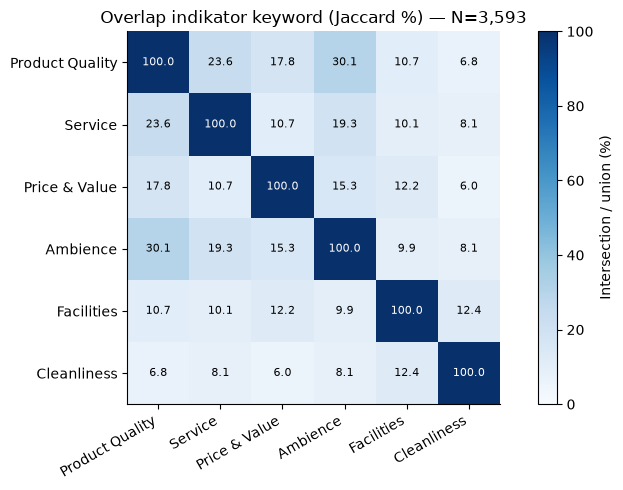

,aspect_a,aspect_b,cooccurring_reviews,jaccard_pct
2,product_quality,ambience,647,30.12
0,product_quality,service,447,23.60
6,service,ambience,361,19.29
1,product_quality,price_value,284,17.77
9,price_value,ambience,235,15.28
3,product_quality,facilities,167,10.69


**Interpretasi.** Overlap adalah kemunculan kata bersama, bukan agreement annotator atau bukti dua aspek benar disebut. Cleanliness hanya 175 indikator dan perlu sampling sengaja. Ke-1.052 review tanpa keyword belum dinilai apakah mengandung aspek implisit atau opini di luar taksonomi. Semua contoh aturan berikutnya sintetis.

In [8]:
sampling_metadata, indicators = sampling_frame(raw, flags, stage2["aspect_keywords"], ASPECT_NAMES)
actual_counts = indicators.sum()
expected_counts = {r["aspect"]: r["review_mentions"] for r in stage2["aspect_distribution"]}
assert all(int(actual_counts[k]) == expected_counts[name] for k, name in ASPECT_NAMES.items())
assert int((~indicators.any(axis=1)).sum()) == stage2["no_aspect_keyword_rows"]
assert int(indicators.sum(axis=1).ge(2).sum()) == stage2["multi_aspect_keyword_rows"]

cooccurrence = indicators.astype(int).T @ indicators.astype(int)
denominator = actual_counts.to_numpy()[:, None] + actual_counts.to_numpy()[None, :] - cooccurrence.to_numpy()
jaccard = np.divide(cooccurrence.to_numpy(), denominator,
                    out=np.zeros_like(denominator, dtype=float), where=denominator != 0)
display(cooccurrence.rename(index=ASPECT_NAMES, columns=ASPECT_NAMES))
fig, ax = plt.subplots(figsize=(8, 5))
img = ax.imshow(jaccard * 100, cmap="Blues", vmin=0, vmax=100)
names = list(ASPECT_NAMES.values())
ax.set_xticks(range(len(names)), labels=names, rotation=30, ha="right")
ax.set_yticks(range(len(names)), labels=names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{jaccard[i,j]*100:.1f}", ha="center", va="center",
                color="white" if jaccard[i,j] > .55 else "black", fontsize=8)
ax.set_title(f"Overlap indikator keyword (Jaccard %) — N={len(raw):,}")
fig.colorbar(img, ax=ax, label="Intersection / union (%)")
fig.tight_layout()
fig.savefig(FIGURES / "stage3_keyword_overlap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
overlap_rows = [
    {"aspect_a": a, "aspect_b": b, "cooccurring_reviews": int(cooccurrence.loc[a, b]),
     "jaccard_pct": float(jaccard[i, j] * 100)}
    for i, a in enumerate(ACTIVE_IDS) for j, b in enumerate(ACTIVE_IDS) if i < j
]
overlap_table = pd.DataFrame(overlap_rows).sort_values("cooccurring_reviews", ascending=False)
overlap_table.to_csv(TABLES / "stage3_keyword_overlap.csv", index=False, encoding="utf-8-sig")
display(overlap_table.head(6).round(2))
display(Markdown(
    "**Interpretasi.** Overlap adalah kemunculan kata bersama, bukan agreement annotator "
    "atau bukti dua aspek benar disebut. Cleanliness hanya 175 indikator dan perlu "
    "sampling sengaja. Ke-1.052 review tanpa keyword belum dinilai apakah mengandung "
    "aspek implisit atau opini di luar taksonomi. Semua contoh aturan berikutnya sintetis."
))


## 8. ABSA Task Formulation

**Task A:** review → himpunan aspek (multi-label, termasuk himpunan kosong).  
**Task B:** review/context + aspect_id → positive/neutral/negative untuk aspek mentioned.

not_mentioned adalah presence dengan sentiment=null; uncertain adalah workflow. Mixed mempertahankan opini positif dan negatif, pair sentiment=null dan tidak eligible untuk subset tiga kelas. Membedakan clause-level task memerlukan protokol tersendiri; seluruh clause satu review tetap pada split sama.

**Implikasi ML.** Model per-aspek atau model gabungan dengan fitur identitas aspek dapat dibandingkan kemudian. Tidak memberi review lengkap identik dengan target bertentangan tanpa konteks pembeda. Fitur/split belum dibangun pada Tahap 3.


In [9]:
task_formulation = pd.DataFrame([
    {"task": "A", "input": "review", "output": "set aspek aktif (0..6)", "formulation": "multi-label"},
    {"task": "B", "input": "context + aspect_id", "output": "positive/neutral/negative", "formulation": "tiga kelas untuk pair terselesaikan"},
])
display(task_formulation)
print("Kebijakan mixed:", taxonomy["policies"]["mixed_training"])
print("Kebijakan uncertain:", taxonomy["policies"]["uncertain_training"])


,task,input,output,formulation
0,A,review,set aspek aktif (0..6),multi-label
1,B,context + aspect_id,positive/neutral/negative,tiga kelas untuk pair terselesaikan


Kebijakan mixed: Pair mixed dikeluarkan dari subset tiga kelas review-aspect. Evidence tetap disimpan. Eksperimen clause-level hanya sebagai task terpisah setelah protokol disepakati.
Kebijakan uncertain: Tidak masuk gold/training sampai adjudikasi; alasan wajib di notes.


## 9. Annotation Rules

**Metode.** Tunjukkan aturan melalui contoh yang sengaja ditulis peneliti. Definisi, negasi, implicit, slang, code-switching, sarkasme, overlap, dan adjudikasi ada di [pedoman anotasi](../docs/research/annotation_guidelines.md).

**Interpretasi.** Toiletnya kotor → cleanliness; toiletnya tidak tersedia → facilities. Wi-Fi lambat → facilities; pelayanan lambat → service. Satu nomina tidak cukup untuk menggandakan label. Pujian umum tidak menyatakan semua aspek positif.


In [10]:
fixtures = synthetic_examples(taxonomy)
assert all(r["data_origin"] == "synthetic" and r["review_id"].startswith("SYN_") for r in fixtures)
rule_preview = pd.DataFrame([{
    "review_id": r["review_id"], "teks_sintetis": r["review_text"],
    "aspek": r["aspect_category"], "presence": r["aspect_presence"],
    "sentimen": r["sentiment"], "mixed": r["mixed_sentiment"], "status": r["annotation_status"],
} for r in fixtures])
display(rule_preview.tail(13))
print("Semua contoh sintetis; tidak ada labeling korpus.")


,review_id,teks_sintetis,aspek,presence,sentimen,mixed,status
18,SYN_MULTI,"Kopinya enak, tempatnya nyaman, tapi parkir su...",product_quality,mentioned,positive,False,completed
19,SYN_MULTI,"Kopinya enak, tempatnya nyaman, tapi parkir su...",ambience,mentioned,positive,False,completed
20,SYN_MULTI,"Kopinya enak, tempatnya nyaman, tapi parkir su...",facilities,mentioned,negative,False,completed
21,SYN_MIXED,"Kopinya enak, tapi minuman lainnya terlalu manis.",product_quality,mentioned,None,True,completed
22,SYN_ABSENT,Kopinya enak.,service,not_mentioned,None,False,completed
23,SYN_IMPLICIT,Pesanan baru datang setelah satu jam.,service,mentioned,negative,False,completed
24,SYN_NEGATION,Tempatnya tidak nyaman.,ambience,mentioned,negative,False,completed
25,SYN_GENERAL,"Bagus banget, recommended!",product_quality,not_mentioned,None,False,completed
26,SYN_UNCERTAIN,Lambat sekali.,service,uncertain,None,False,uncertain
27,SYN_CODE,Wi-Fi is very slow.,facilities,mentioned,negative,False,completed


Semua contoh sintetis; tidak ada labeling korpus.


## 10. Annotation Schema Validation

**Metode.** JSON Schema Draft 2020-12 memvalidasi field dan konsistensi presence/sentiment/status. Validator tambahan memastikan quote sama dengan slice Unicode asli, opini bertentangan ditandai mixed, dan pair tidak ganda.

**Hasil.** Validasi ini hanya menguji struktur dan contoh sintetis. Tidak mengukur agreement manusia atau akurasi deteksi aspek.


In [11]:
Draft202012Validator.check_schema(schema)
assert validate_batch(fixtures, schema)
long_synthetic = synthetic_long_format(fixtures, schema)
assert long_synthetic.loc[long_synthetic["aspect_presence"].eq("not_mentioned"), "sentiment"].isna().all()
mixed_rows = long_synthetic["review_id"].eq("SYN_MIXED")
assert long_synthetic.loc[mixed_rows, "sentiment"].isna().all()
assert not long_synthetic.loc[mixed_rows, "training_eligible"].any()
assert len(long_synthetic.loc[long_synthetic["review_id"].eq("SYN_MULTI")]) == 3
display(long_synthetic.tail(13))
print(f"Schema valid; {len(fixtures)} record sintetis lulus.")


,review_id,coffee_shop_id,aspect_category,aspect_presence,context,sentiment,training_eligible,taxonomy_version
18,SYN_MULTI,SYN_COFFEE_SHOP,product_quality,mentioned,"Kopinya enak, tempatnya nyaman, tapi parkir su...",positive,True,0.1.0-draft
19,SYN_MULTI,SYN_COFFEE_SHOP,ambience,mentioned,"Kopinya enak, tempatnya nyaman, tapi parkir su...",positive,True,0.1.0-draft
20,SYN_MULTI,SYN_COFFEE_SHOP,facilities,mentioned,"Kopinya enak, tempatnya nyaman, tapi parkir su...",negative,True,0.1.0-draft
21,SYN_MIXED,SYN_COFFEE_SHOP,product_quality,mentioned,"Kopinya enak, tapi minuman lainnya terlalu manis.",None,False,0.1.0-draft
22,SYN_ABSENT,SYN_COFFEE_SHOP,service,not_mentioned,Kopinya enak.,None,False,0.1.0-draft
23,SYN_IMPLICIT,SYN_COFFEE_SHOP,service,mentioned,Pesanan baru datang setelah satu jam.,negative,True,0.1.0-draft
24,SYN_NEGATION,SYN_COFFEE_SHOP,ambience,mentioned,Tempatnya tidak nyaman.,negative,True,0.1.0-draft
25,SYN_GENERAL,SYN_COFFEE_SHOP,product_quality,not_mentioned,"Bagus banget, recommended!",None,False,0.1.0-draft
26,SYN_UNCERTAIN,SYN_COFFEE_SHOP,service,uncertain,Lambat sekali.,None,False,0.1.0-draft
27,SYN_CODE,SYN_COFFEE_SHOP,facilities,mentioned,Wi-Fi is very slow.,negative,True,0.1.0-draft


Schema valid; 31 record sintetis lulus.


## 11. Pilot Sampling Strategy

**Tujuan.** Menyiapkan 250 kandidat tanpa label dengan cakupan kedai, rating, panjang, rare/no/multi-keyword, slang/campuran, dan pengulangan teks.

**Metode.** Universe eligible Tahap 2; minimum tiga per kedai, lalu pemenuhan kuota kelompok yang boleh overlap dan pengisian slot tersisa. Ranking SHA-256(seed|review_id), seed=42, stabil terhadap perubahan urutan input. Kuota dan keterbatasan ada di YAML serta dokumen keputusan.

**Batas.** Pilot kuota/oversampling bukan distribusi alami. Semua kandidat tetap UNLABELED_NOT_AUTHORIZED. Metadata rating/keyword untuk perancang sampling harus disembunyikan dari annotator kelak; tidak ada teks asli dalam CSV.


,group,target_minimum,available_in_eligible_pool,selected_count,shortfall
0,rare_cleanliness,20,175,20,0
1,facilities_candidate,20,277,22,0
2,no_keyword,35,1041,75,0
3,low_rating,30,242,30,0
4,mid_rating,15,104,15,0
5,long_review,25,419,34,0
6,multi_keyword,50,1309,104,0
7,slang_or_mixed,40,1207,87,0
8,potential_duplicate,15,253,26,0
9,short_review,35,767,58,0


,review_id,place_key,word_count,sampling_reason,candidate_status
0,Ci9DQUlRQUNvZENodHljRjlvT2xFd1dVaHBOMjFGVkdFNV...,place_id:ChIJn-uHCALFaC4RRJN_2efiaXI,2,minimum_per_shop,UNLABELED_NOT_AUTHORIZED
1,Ci9DQUlRQUNvZENodHljRjlvT21sblgzWTNORWxvTjNWNG...,place_id:ChIJEYk-kg7FaC4Rzcpqv6QePJQ,4,minimum_per_shop,UNLABELED_NOT_AUTHORIZED
2,Ci9DQUlRQUNvZENodHljRjlvT25CaGVtSkVWbk5GVWtWel...,place_id:ChIJNZfmYuHFaC4RR7-4TNQ_NKE,2,minimum_per_shop,UNLABELED_NOT_AUTHORIZED
3,Ci9DQUlRQUNvZENodHljRjlvT2xRMFVGcFdXbFpEVkVobF...,place_id:ChIJNZfmYuHFaC4RR7-4TNQ_NKE,3,minimum_per_shop,UNLABELED_NOT_AUTHORIZED
4,Ci9DQUlRQUNvZENodHljRjlvT2toQ1p6QTNhM1kwTURaRk...,place_id:ChIJEYk-kg7FaC4Rzcpqv6QePJQ,25,minimum_per_shop,UNLABELED_NOT_AUTHORIZED


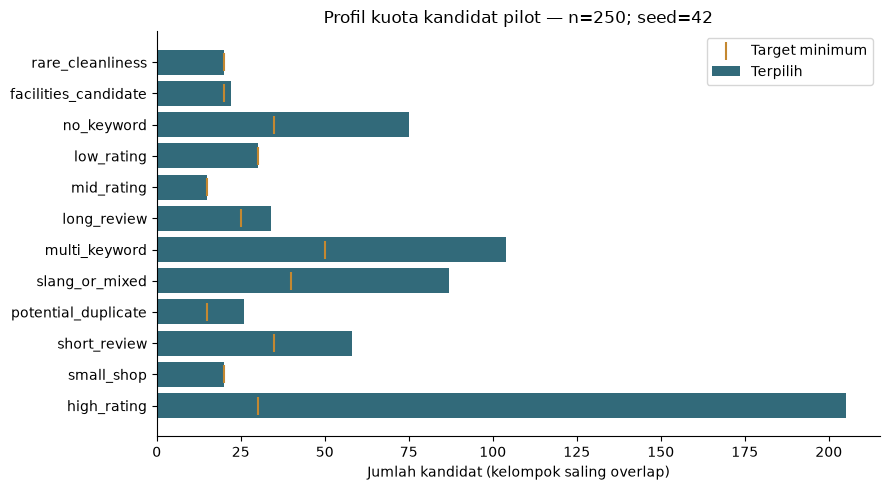

Kandidat: 250; kedai: 40; minimum/kedai: 3.
Total shortfall kuota: 0


**Interpretasi.** 250 kandidat unik dipilih secara reproducible, mencakup 40 kedai. Shortfall total=0. Pemilihan bukan pelabelan dan tidak mengesahkan inklusi geografis. Review tanpa keyword/rare-aspect adalah strata eksploratif, bukan ground truth.

In [12]:
policy = taxonomy["sampling"]
pilot, quota_report = select_pilot(sampling_metadata, policy)
pilot_again, quota_again = select_pilot(
    sampling_metadata.sample(frac=1, random_state=2026).reset_index(drop=True), policy,
)
pd.testing.assert_frame_equal(pilot, pilot_again)
pd.testing.assert_frame_equal(quota_report, quota_again)
assert len(pilot) == min(policy["target"], stage2["basic_quality_pass_rows"])
assert pilot["place_key"].nunique() == flags["place_key"].nunique()
minimum_observed = int(pilot.groupby("place_key").size().min())
assert minimum_observed >= policy["minimum_per_shop"]
geo_status = geo.set_index("place_key")["verification_status"]
pilot["geography_status"] = pilot["place_key"].map(geo_status)
assert pilot["geography_status"].notna().all()
pilot["annotation_permission_status"] = stage2["readiness_dimensions"]["research_data_usage"]["permission_status"]
assert set(pilot["candidate_status"]) == {"UNLABELED_NOT_AUTHORIZED"}
assert not {"teks_review", "review_text", "sentiment", "evidence", "aspect_category", "aspect_presence", "annotation_status"}.intersection(pilot.columns)
pilot.to_csv(CANDIDATE_PATH, index=False, encoding="utf-8-sig")
quota_report.to_csv(TABLES / "stage3_pilot_quota_report.csv", index=False, encoding="utf-8-sig")
display(quota_report)
display(pilot[["review_id", "place_key", "word_count", "sampling_reason", "candidate_status"]].head())
fig, ax = plt.subplots(figsize=(9, 5))
view = quota_report.iloc[::-1]
ax.barh(view["group"], view["selected_count"], color="#326A7A", label="Terpilih")
ax.scatter(view["target_minimum"], view["group"], marker="|", s=180, color="#C48831", label="Target minimum")
ax.set(title=f"Profil kuota kandidat pilot — n={len(pilot)}; seed={SEED}",
       xlabel="Jumlah kandidat (kelompok saling overlap)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "stage3_pilot_profile.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Kandidat: {len(pilot)}; kedai: {pilot['place_key'].nunique()}; minimum/kedai: {minimum_observed}.")
print("Total shortfall kuota:", int(quota_report["shortfall"].sum()))
display(Markdown(
    f"**Interpretasi.** {len(pilot)} kandidat unik dipilih secara reproducible, mencakup "
    f"{pilot['place_key'].nunique()} kedai. Shortfall total={int(quota_report['shortfall'].sum())}. "
    "Pemilihan bukan pelabelan dan tidak mengesahkan inklusi geografis. Review tanpa "
    "keyword/rare-aspect adalah strata eksploratif, bukan ground truth."
))


## 12. Quality Assurance Plan

**Rencana Tahap 4, belum dilaksanakan.** Setelah gate selesai: dua manusia independen, rating/output AI disembunyikan; rencana 50 kalibrasi dan 200 penilaian dengan guideline dibekukan. Angka pembagian nominal harus menghormati kelompok review/teks berulang.

Ukur Kappa presence per aspek, Kappa sentimen pada pair yang sama-sama mentioned, precision/recall/F1 aspect detection, Macro-F1 per aspek dan confusion matrix terhadap gold. Laporkan denominator, prevalence, kelas langka, dan nilai undefined. Adjudikasi setelah agreement pra-diskusi tersimpan.

Rencana gold 200 hasil adjudikasi dengan sekitar 50 locked validation untuk perbandingan AI-manusia; tidak boleh dipakai tuning. Seluruh aspek/clauses dari satu review dan grup duplikasi berada pada split sama. Tidak ada metrik agreement/performa yang dihitung sekarang.


In [13]:
qa_plan = pd.DataFrame([
    {"komponen": "Presence agreement per aspek", "metrik": "raw agreement + Cohen Kappa", "status": "NOT_CALCULATED_NO_ANNOTATIONS"},
    {"komponen": "Aspect detection vs gold", "metrik": "per-aspect/micro/macro P-R-F1", "status": "NOT_CALCULATED_NO_ANNOTATIONS"},
    {"komponen": "Sentimen pair vs gold", "metrik": "Macro-F1 dan confusion matrix", "status": "NOT_CALCULATED_NO_ANNOTATIONS"},
    {"komponen": "AI versus manusia", "metrik": "metrik task yang sama + error audit", "status": "NOT_STARTED_PERMISSION_GATE"},
])
display(qa_plan)
print("Guideline version:", taxonomy["taxonomy_version"])
print("Tidak ada angka agreement, akurasi, atau performa model yang dibuat.")


,komponen,metrik,status
0,Presence agreement per aspek,raw agreement + Cohen Kappa,NOT_CALCULATED_NO_ANNOTATIONS
1,Aspect detection vs gold,per-aspect/micro/macro P-R-F1,NOT_CALCULATED_NO_ANNOTATIONS
2,Sentimen pair vs gold,Macro-F1 dan confusion matrix,NOT_CALCULATED_NO_ANNOTATIONS
3,AI versus manusia,metrik task yang sama + error audit,NOT_STARTED_PERMISSION_GATE


Guideline version: 0.1.0-draft
Tidak ada angka agreement, akurasi, atau performa model yang dibuat.


## 13. Methodological Limitations

Literatur melintasi benchmark kalimat, review restoran, dan survei coffee shop. Transfer konteks bukan bukti validitas lokal. Dua sumber hanya metadata/abstrak; detail full text yang belum dibaca tidak diklaim. Ketidakjelasan metode labeling pada salah satu studi Indonesia dicatat pada literature review.

Coverage dan overlap leksikal tidak mengevaluasi aspek implisit, negasi, atau sentimen. Contoh sintetis menguji aturan, bukan kemampuan manusia/model. General praise dan kandidat lokasi bisa memerlukan revisi taksonomi. Dominasi rating tinggi serta quota sampling membatasi generalisasi.

Geografi, metadata historis, dan izin penggunaan belum final. File kandidat tidak mengandung teks/label tetapi tetap dikelola sebagai metadata penelitian internal. Tidak dilakukan aktivitas Tahap 4.


In [14]:
gates = {
    "geography": geo["verification_status"].value_counts().to_dict(),
    "permission": stage2["readiness_dimensions"]["research_data_usage"]["permission_status"],
    "real_annotation_performed": False,
    "sentiment_classification_performed": False,
    "model_training_performed": False,
    "empirical_taxonomy_validated": False,
}
display(pd.Series({k: str(v) for k, v in gates.items()}, name="status").to_frame())
assert (pilot["candidate_status"] == "UNLABELED_NOT_AUTHORIZED").all()
assert gates["permission"] == "PERMISSION_NOT_VERIFIED"


,status
geography,{'UNVERIFIED': 40}
permission,PERMISSION_NOT_VERIFIED
real_annotation_performed,False
sentiment_classification_performed,False
model_training_performed,False
empirical_taxonomy_validated,False


## 14. Conclusions & Readiness for Stage 4

**Hasil.** Metodologi draft, taksonomi machine-readable, schema, pedoman, matriks literatur, dan kandidat pilot tersedia. Test sintetis dan sampling deterministik memverifikasi implementasi teknis, bukan validitas anotasi korpus.

**Keputusan.** Siap untuk review metodologi tim dan penyelesaian gate; belum siap menjalankan labeling nyata. Location tetap provisional. Aktivasi/revisi kategori, aturan overlap, implicit/mixed, dan kuota harus diperiksa pada pilot berizin.

Code berikut menyimpan ringkasan dari hasil aktual dan memverifikasi checksum raw, tanpa menjalankan ulang Tahap 2.


In [15]:
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == SOURCE_SHA256
manifest = {
    "stage": 3, "taxonomy_version": taxonomy["taxonomy_version"],
    "source_sha256": SOURCE_SHA256,
    "taxonomy_sha256": hashlib.sha256(CONFIG_PATH.read_bytes()).hexdigest(),
    "schema_sha256": hashlib.sha256(SCHEMA_PATH.read_bytes()).hexdigest(),
    "literature_source_count": len(literature), "literature_verification": status_counts.to_dict(),
    "active_aspects": ACTIVE_IDS, "provisional_aspects": [a["id"] for a in provisional],
    "synthetic_fixture_records": len(fixtures),
    "pilot_candidate_count": len(pilot), "pilot_place_count": int(pilot["place_key"].nunique()),
    "pilot_minimum_per_shop": minimum_observed, "seed": SEED,
    "pilot_sha256": hashlib.sha256(CANDIDATE_PATH.read_bytes()).hexdigest(),
    "quota_shortfall": int(quota_report["shortfall"].sum()),
    "keyword_coverage": {key: int(value) for key, value in actual_counts.items()},
    "no_keyword_rows": int((~indicators.any(axis=1)).sum()),
    "multi_keyword_rows": int(indicators.sum(axis=1).ge(2).sum()),
    "gates": gates, "status": "METHODOLOGY_DRAFT_READY_FOR_REVIEW; REAL_ANNOTATION_BLOCKED",
}
(ROOT / "reports/stage3_taxonomy_summary.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8",
)
aspect_rows = "\n".join(
    f"| {a['id']} | {a['name']} | {a['decision']} | {'aktif' if a['active'] else 'provisional'} |"
    for a in taxonomy["aspects"]
)
coverage_rows = "\n".join(
    f"| {ASPECT_NAMES[key]} | {int(actual_counts[key]):,} |"
    for key in ACTIVE_IDS
)
quota_rows = "\n".join(
    f"| {r.group} | {r.target_minimum} | {r.selected_count} | {r.shortfall} |"
    for r in quota_report.itertuples(index=False)
)
report = f"""# Ringkasan Tahap 3 — Taksonomi dan pedoman anotasi

Versi: {taxonomy['taxonomy_version']}. Status: draft berbasis literatur; belum empirically validated.

## Bukti literatur

{len(literature)} referensi terverifikasi bibliografinya:
{int(status_counts.get('VERIFIED_FULL_TEXT', 0))} full text relevan dan
{int(status_counts.get('VERIFIED_METADATA_AND_ABSTRACT', 0))} metadata/abstrak.
Sumber, DOI, lokasi bukti, dan batas akses ada di
[tinjauan literatur](../docs/research/aspect_taxonomy_literature_review.md),
[references.bib](../docs/research/references.bib), dan [matriks](tables/literature_matrix.csv).
Pemetaan researcher adaptation: [literature_aspect_mapping.csv](tables/literature_aspect_mapping.csv).

## Keputusan taksonomi

| ID | Aspek | Keputusan | Status |
| --- | --- | --- | --- |
{aspect_rows}

Food/drinks/menu digabung Product Quality; waiting time masuk Service.
Miscellaneous/general praise tidak menjadi label semua aspek.
Facilities/Cleanliness dipisahkan berdasarkan objek+predikat, sebagai adaptasi penelitian.
Location & Accessibility didukung teori tetapi memerlukan validasi pilot dan scope.

## Bukti korpus yang diizinkan

| Indikator keyword Tahap 2 | Jumlah review |
| --- | --- |
{coverage_rows}

Review tanpa keyword: {manifest['no_keyword_rows']:,}; multi-keyword: {manifest['multi_keyword_rows']:,}.
Keyword bukan ground truth. Review tanpa keyword belum dinilai sebagai implicit atau out-of-taxonomy.
Overlap rinci ada pada [tabel](tables/stage3_keyword_overlap.csv).

![Overlap keyword](figures/stage3_keyword_overlap.png)

## Pedoman dan schema

[Pedoman Indonesia](../docs/research/annotation_guidelines.md),
[keputusan metodologi/QA](../docs/research/stage3_methodology_decisions.md),
[YAML](../configs/aspect_taxonomy.yaml), dan [JSON Schema](../schemas/annotation_schema.json).

Task A multi-label presence; Task B tiga kelas pada aspek mentioned.
Neutral berbeda dari not_mentioned (sentiment=null); uncertain adalah status workflow.
Mixed mempertahankan evidence positif+negatif, pair sentiment=null dan tidak masuk
subset training tiga kelas. Contoh sintetis mendemonstrasikan konversi long format;
tidak ada dataset review asli berlabel yang dibuat.

## Kandidat pilot

{len(pilot)} kandidat unik dari {pilot['place_key'].nunique()} kedai; minimum
{minimum_observed} per kedai; seed={SEED}. Universe eligible
{stage2['basic_quality_pass_rows']:,} review. Ranking SHA-256(seed|review_id)
dan kuota overlap-aware. CSV kandidat tidak memiliki teks atau label.
Rating/keyword metadata hanya untuk perancang sampling dan kelak disembunyikan dari annotator.

| Kelompok | Minimum | Terpilih | Shortfall |
| --- | --- | --- | --- |
{quota_rows}

Pilot kuota/oversampling tidak mencerminkan distribusi alami.
Bukti reproducibility: hasil identik setelah urutan input diacak.

![Profil pilot](figures/stage3_pilot_profile.png)

## QA dan readiness

Rencana setelah izin: dua manusia independen, kalibrasi terpisah, penilaian
presence/sentimen sebelum adjudikasi, gold dan locked validation, lalu
perbandingan AI-manusia. Seluruh record dari review/kelompok duplikasi sama
dijaga dalam split sama. Tidak ada agreement atau performa model yang dihitung.

Geografi: {json.dumps(gates['geography'])}.
Izin: {gates['permission']}. Metodologi dapat direview tim; anotasi aktual tetap
menunggu gate geografis, hak penggunaan, privasi/duplikasi, dan protokol manusia.
Batas kategori overlap, implicit/mixed, coverage gap, dan aspek lokasi masih
memerlukan validasi pilot. Tidak ada klaim kesiapan rekomendasi bisnis/model.

## Pemeriksaan teknis

YAML, referensi sumber, JSON Schema, {len(fixtures)} record sintetis, aturan mixed,
neutral versus absence, multi-aspek, dan sampling reproducibility lulus pada notebook.
Hash raw tetap {SOURCE_SHA256}. Tidak ada raw/Tahap 2 yang diubah.
Kernel: BrewScope (.venv). Jalankan Restart Kernel and Run All pada
notebooks/02_aspect_taxonomy.ipynb; test otomatis menggunakan pytest.

Hash config: {manifest['taxonomy_sha256']}.
Hash schema: {manifest['schema_sha256']}.
Hash kandidat: {manifest['pilot_sha256']}.
"""
(ROOT / "reports/stage3_taxonomy_summary.md").write_text(report, encoding="utf-8")
print("Tahap 3 metodologi selesai; kandidat tetap tanpa label.")
display(pd.Series(manifest, name="ringkasan aktual").to_frame())


Tahap 3 metodologi selesai; kandidat tetap tanpa label.


,ringkasan aktual
stage,3
taxonomy_version,0.1.0-draft
source_sha256,7b87a53110041da74e976a6c9cb121c1dea7d73be70dae...
taxonomy_sha256,e73ae34262f300d5551ade75d732a1b99ba84799a03456...
schema_sha256,44bbdb75cbdc2ef87c7f958ac0491c6088ea9f6ddbb532...
literature_source_count,7
literature_verification,"{'VERIFIED_FULL_TEXT': 5, 'VERIFIED_METADATA_A..."
active_aspects,"[product_quality, service, price_value, ambien..."
provisional_aspects,[location_accessibility]
synthetic_fixture_records,31
